# Prueba de recepción del docente
Archivo de prueba administrativa, no entrega de estudiante. Contiene salidas de la ejecución local de la versión docente; permite comprobar conservación de tabla, gráfico y dos fragmentos. No incluye identidades ni respuestas personales de estudiantes.


## Salida conservada: tasas


In [7]:
# @title Comparación: conteos y menciones por 1.000 palabras
palabra = "competencia"
ids_comparar = ["leguia_1921", "alberto_fujimori_1991"]
comparacion = comparar_palabra(documentos, palabra, ids_comparar)
display(comparacion.round({"menciones_por_1000": 3}))


,documento_id,fecha,palabra,menciones,n_palabras_conteo,menciones_por_1000
0,leguia_1921,1921-07-28,competencia,2,4527,0.442
1,alberto_fujimori_1991,1991-07-28,competencia,11,23348,0.471


## Salida conservada: grafico


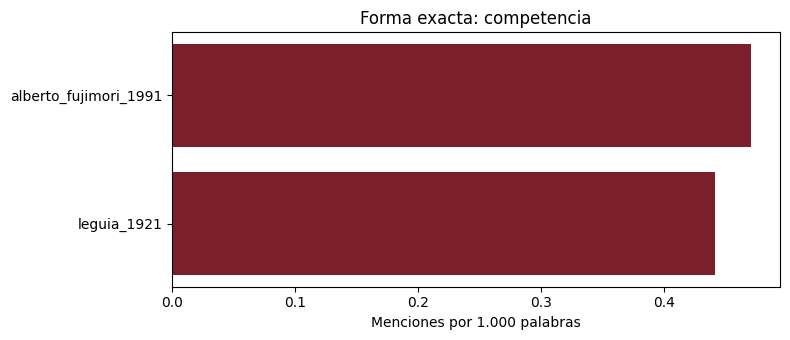

In [8]:
# @title Gráfico de la comparación
import matplotlib.pyplot as plt

figura, eje = plt.subplots(figsize=(8, 3.5))
eje.barh(comparacion["documento_id"], comparacion["menciones_por_1000"], color="#7A1F2B")
eje.set_xlabel("Menciones por 1.000 palabras")
eje.set_title("Forma exacta: " + comparacion.attrs["palabra"])
eje.set_xlim(left=0)
figura.tight_layout()
figura.savefig("mi_comparacion.png", dpi=150, bbox_inches="tight")
plt.show()


## Salida conservada: evidencia


In [11]:
# @title Dos fragmentos completos y su procedencia
indices_fragmentos = [0, 3]
evidencia = pd.DataFrame()
if len(indices_fragmentos) != 2 or not all(i in contextos.index for i in indices_fragmentos):
    print("Elige dos filas válidas de contextos. Si no hay coincidencias, revisa palabra y documentos.")
elif contextos.loc[indices_fragmentos, "documento_id"].nunique() != 2:
    print("Elige una fila de cada documento distinto.")
else:
    evidencia = contextos.loc[indices_fragmentos].copy()
    for indice, hallazgo in evidencia.iterrows():
        documento = documentos.loc[documentos["documento_id"] == hallazgo["documento_id"]].iloc[0]
        unidad = unidades.loc[unidades["unidad_id"] == hallazgo["unidad_id"]]
        pagina = paginas.loc[(paginas["documento_id"] == hallazgo["documento_id"])
                             & (paginas["pagina_pdf"] == hallazgo["pagina_pdf"])]
        texto = unidad.iloc[0]["texto"] if len(unidad) else pagina.iloc[0]["texto"]
        evidencia.loc[indice, "fragmento_completo"] = texto
        evidencia.loc[indice, "url_pdf"] = documento["url_pdf"]
        print("\nDocumento:", hallazgo["documento_id"], "Página:", hallazgo["pagina_pdf"], "Unidad:", hallazgo["unidad_id"])
        print(texto)
        print("Original:", documento["url_pdf"])
    evidencia.attrs["palabra"] = contextos.attrs["palabra"]
    evidencia.attrs["ids"] = contextos.attrs["ids"]



Documento: leguia_1921 Página: 11 Unidad: u00126
A ello contribuirá, sin duda, la reorganización que estudia, en la actualidad, el personal de especialistas contratado últimamente, cuya competencia se ha evidenciado en la campaña que, para extirpar la fiebre amarilla, desarrollóse en el norte de la República, con la colaboración espontánea y generosa de la humanitaria institución Rockefeller, existente en los Estados Unidos. Fomento de la agricultura y la ganadería No ha descuidado mi Gobierno el incremento de la agricultura y ganadería. Huellas de su acción encontraréis en la Granja Modelo de Puno, cuya instalación ha sido motivo de general alborozo en el sur de la República; en la importación de sementales de pura sangre; en la reglamentación provisional del registro de marcas y señales, mientras se edita el código respectivo; en la organización de la estadística agrícola; y en otras medidas que la Memoria del ramo os hará conocer pormenorizadamente.
Original: https://www3.congreso.